# Fitness Customer Churn Analysis

Caso de portafolio con datos de práctica. El README indica cómo ejecutar el notebook con copias locales de las tres fuentes.

## 1. Data Loading and Initial Inspection

**Objetivo del proyecto**

Investigar los patrones asociados a la cancelación de suscripciones (customer churn) en una aplicación de fitness, considerando la actividad de los usuarios, las interacciones con soporte y los planes contratados.

**Fuentes de datos**

- `account_info`: información de cuentas, planes y estado de cancelación.
- `customer_support`: registros de interacciones con soporte.
- `user_activity`: eventos de actividad dentro de la aplicación.

**Metodología**

Se realizará una exploración inicial de las tres fuentes, seguida de la validación y limpieza de sus columnas, la integración de datos, el análisis exploratorio y la formulación de recomendaciones comerciales.

Las transformaciones se realizarán sobre copias de los DataFrames originales, documentando las decisiones y las limitaciones encontradas.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd

DATA_DIR = Path("data")
FIGURES_DIR = Path("figures")


In [ ]:
source_files = (
    "da_fitly_account_info.csv",
    "da_fitly_customer_support.csv",
    "da_fitly_user_activity.csv",
)
missing_files = [name for name in source_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(
        "Place your local copies of these source files in data/: " + ", ".join(missing_files)
    )

account_info = pd.read_csv(DATA_DIR / source_files[0])
customer_support = pd.read_csv(DATA_DIR / source_files[1])
user_activity = pd.read_csv(DATA_DIR / source_files[2])
FIGURES_DIR.mkdir(exist_ok=True)


In [ ]:
account_info.info()

In [ ]:
account_info.shape

In [ ]:
customer_support.info()

In [ ]:
customer_support.shape

In [ ]:
user_activity.info()

In [ ]:
user_activity.shape

In [ ]:
# Validate customer identifiers before joining datasets

account_ids_numeric = pd.to_numeric(
    account_info["customer_id"].str.removeprefix("C"),
    errors="coerce"
)

print("ID no convertibles:", account_ids_numeric.isna().sum())
print("ID duplicados:", account_ids_numeric.duplicated().sum())
print("Registros de soporte sin correspondencia:",(~customer_support["user_id"].isin(account_ids_numeric)).sum())
print("Eventos de actividad sin correspondencia:",(~user_activity["user_id"].isin(account_ids_numeric)).sum())


### 1.1 Customer Identifier Validation

**Validación de identificadores**

Se comprobó que los 400 identificadores de `account_info` pueden convertirse a valores numéricos sin generar valores faltantes ni duplicados.

También se verificó la correspondencia entre los identificadores de las tres fuentes:

- `customer_support`: 0 registros sin correspondencia.
- `user_activity`: 0 registros sin correspondencia.

Los resultados indican que las fuentes pueden relacionarse mediante los identificadores normalizados, conservando las observaciones originales.

**Findings (English)**

All 400 customer identifiers were successfully converted to numeric values, with no missing or duplicate identifiers.

All 918 customer support records and 445 user activity events matched existing customer accounts.

The three datasets can be linked using standardized customer identifiers.

No records were removed during this validation.


In [ ]:
# Inspect churn status values and missing data
account_info["churn_status"].value_counts(dropna=False)

In [ ]:
# Inspect raw churn status values
account_raw = pd.read_csv(
    DATA_DIR / source_files[0],
    keep_default_na=False
)

account_raw["churn_status"].value_counts(dropna=False)

In [ ]:
# Inspect cancellation markers by subscription plan

pd.crosstab(
    account_info["plan"],
    account_info["churn_status"].fillna("Not flagged")
)

In [ ]:
# Compare cancellation proportions within each plan
pd.crosstab(
    account_info["plan"],
    account_info["churn_status"].fillna("Not flagged"),
    normalize="index"
).round(3)


In [ ]:
# Inspect recorded prices by subscription plan
account_info.groupby("plan")["plan_list_price"].agg(
    ["count", "min", "max", "nunique"]
)

In [ ]:

# Validate geographic information

print("Estados únicos:", account_info["state"].nunique())
print("Estados faltantes:", account_info["state"].isna().sum())

account_info["state"].value_counts(dropna=False)


In [ ]:

# Validate emails and duplicate records

print("Emails faltantes:", account_info["email"].isna().sum())
print("Emails duplicados:", account_info["email"].duplicated().sum())
print("Filas duplicadas:", account_info.duplicated().sum())



### 1.2 Account Information Validation

**Validación de datos**

Se revisaron las seis columnas de `account_info`, que contiene 400 registros de clientes.

- `customer_id`: 400 identificadores únicos. Todos permiten recuperar su componente numérico sin errores de conversión.
- `email`: no se encontraron valores faltantes ni direcciones duplicadas.
- `state`: se identificaron 50 categorías geográficas correspondientes aparentemente a estados estadounidenses, sin valores faltantes.
- `plan`: se confirmaron las cuatro categorías esperadas: Free, Basic, Pro y Enterprise.
- `plan_list_price`: Free presenta exclusivamente valores iguales a cero. Los planes pagados presentan distintos precios, con rangos diferenciados y sin superposiciones.
- `churn_status`: se encontraron 114 registros marcados como `Y` y 286 campos vacíos.

No se identificaron filas completamente duplicadas.

**Decisiones y limitaciones**

Se conservarán los precios registrados. La variación dentro de cada plan no constituye por sí sola un error.

La interpretación de los campos vacíos de `churn_status` permanece pendiente de confirmación. No serán clasificados automáticamente como clientes activos sin documentar el supuesto correspondiente.

No se eliminaron registros ni se modificaron los datos originales durante esta validación.

**Findings (English)**

The `account_info` dataset contains 400 customer records and six columns.

All customer identifiers were unique and could be converted to numeric values without errors.

No missing emails, duplicate emails, or fully duplicated records were identified.

The dataset contains 50 geographic categories, with no missing state values. All four expected subscription plans were present.

Free accounts had a recorded price of zero. Paid plans showed different price ranges without observed overlap.

The `churn_status` column contained 114 records marked as `Y` and 286 blank values.

**Data quality consideration:** blank churn values have not been explicitly confirmed as active subscriptions. This uncertainty must be documented before calculating the churn rate.

No original records were removed or modified.



### 1.3 Customer Support Validation

Se analizarán los registros de soporte para comprobar la consistencia de sus variables, identificar problemas de calidad y preparar su posterior integración con la información de los clientes.

Se prestará especial atención al estado de los tickets, los tiempos de resolución, las fechas y los posibles registros duplicados.

Los códigos sin definición confirmada se conservan sin reinterpretarlos.


In [ ]:

# Inspect support ticket states
customer_support["state"].value_counts(dropna=False)


In [ ]:

# Inspect support resolution times
customer_support["resolution_time_hours"].describe()


In [ ]:
print("Tickets con tiempo de resolución menor o igual a cero:",(customer_support["resolution_time_hours"]<=0).sum())

In [ ]:

# Calculate the interquartile range of resolution times

q1 = customer_support["resolution_time_hours"].quantile(0.25)
q3 = customer_support["resolution_time_hours"].quantile(0.75)

iqr = q3 - q1

# Calculate lower and upper outlier limits
lower_limit = q1 - 1.5*(iqr)
upper_limit = q3 + 1.5*(iqr)

# Count potential outliers
print("Cantidad de posibles valores atípicos:",
      ((customer_support["resolution_time_hours"] < lower_limit) |
       (customer_support["resolution_time_hours"]>upper_limit)).sum())





In [ ]:

# Validate support ticket timestamps

ticket_dates = pd.to_datetime(
    customer_support["ticket_time"],
    errors="coerce"
)

print("Fechas inválidas:", ticket_dates.isna().sum())
print("Fecha mínima:", ticket_dates.min())
print("Fecha máxima:", ticket_dates.max())


In [ ]:

# Inspect support channels
print(customer_support["channel"].value_counts(dropna=False))

# Inspect support topics
print(customer_support["topic"].value_counts(dropna=False))


In [ ]:

# Check fully duplicated support records
customer_support.duplicated().sum()


In [ ]:
# Count support topics with unspecified channels

customer_support.loc[
    customer_support["channel"] == "-",
    "topic"
].value_counts()

In [ ]:
# Validate optional support comments

print("Comentarios presentes:", customer_support["comments"].notna().sum())
print("Comentarios faltantes:", customer_support["comments"].isna().sum())


### 1.3.1 Customer Support Validation Results

**Resultados de la validación**

Se analizaron 918 registros de soporte correspondientes a clientes identificados en `account_info`.

- `ticket_time`: las 918 fechas se convirtieron correctamente. El período observado comprende desde el 5 de junio hasta el 1 de diciembre de 2025.
- `user_id`: todos los registros tienen correspondencia con la tabla de cuentas.
- `channel`: se identificaron tres canales válidos (`email`, `chat` y `phone`) y 39 registros con el marcador `"-"`.
- `topic`: se identificaron cuatro categorías: `billing`, `account`, `technical` y `other`.
- `resolution_time_hours`: el tiempo promedio fue de 10,39 horas y la mediana de 9,04 horas. No existen tiempos menores o iguales a cero.
- `state`: contiene 504 registros con valor `1` y 414 con valor `0`. Su significado operativo todavía no está confirmado.
- `comments`: contiene 46 valores registrados y 872 valores faltantes.

No se encontraron filas completamente duplicadas.

**Hallazgos adicionales**

Mediante el criterio de 1,5 veces el rango intercuartílico se identificaron 44 tiempos de resolución potencialmente atípicos.

Estos registros podrían representar casos legítimos y no serán eliminados automáticamente.

Los 39 canales desconocidos aparecen en las cuatro categorías de contacto, principalmente en `account` (15 casos).

**Decisiones y limitaciones**

Se conservarán los registros originales durante la preparación de datos.

El marcador `"-"` de `channel` se tratará como información desconocida.

Los valores faltantes de `comments` no se imputarán, dado que podría tratarse de un campo opcional. Los comentarios relacionados con información personal requerirán un tratamiento adecuado.

Los códigos de `state` se conservarán sin asignarles significados no confirmados.

**Findings (English)**

The `customer_support` dataset contains 918 support records.

All customer identifiers matched existing accounts, and all ticket timestamps were successfully converted to datetime values.

Three support channels were identified: email, chat, and phone. An additional 39 records contained an unspecified channel marker.

Four support topics were found: billing, account, technical, and other.

The average resolution time was 10.39 hours, with a median of 9.04 hours. No zero or negative resolution times were identified.

Using the 1.5 × IQR rule, 44 potential outliers were detected. These records were retained because unusually long resolution times may represent legitimate support cases.

The `comments` column contained 872 missing values and may represent optional information.

No fully duplicated records were identified.

**Limitations**

The operational meaning of the support `state` codes remains unconfirmed.

Missing support channels and potentially unusual resolution times will be considered during data preparation.

No original records were removed or modified.



### 1.4 User Activity Validation

Se validarán los registros de actividad de los usuarios para comprobar la consistencia de las fechas, los identificadores y los tipos de eventos.

El objetivo es preparar esta fuente para investigar posteriormente si existen diferencias en los patrones de actividad entre clientes con y sin cancelación registrada.


In [ ]:
event_type_datetime = pd.to_datetime(user_activity["event_time"], errors="coerce")
print("Fechas iválidas:",event_type_datetime.isna().sum())
print("Fecha min:", event_type_datetime.min())
print("Fecha max:", event_type_datetime.max())

In [ ]:
# Inspect activity event types
user_activity["event_type"].value_counts(dropna=False)

In [ ]:
# Check fully duplicated activity records
user_activity.duplicated().sum()

In [ ]:
# Count unique active users
user_activity["user_id"].nunique()


### 1.4.1 User Activity Validation Results

**Resultados de la validación**

Se analizaron 445 eventos de actividad correspondientes a 246 usuarios únicos.

- `event_time`: las 445 fechas se convirtieron correctamente, sin generar valores inválidos. El período observado comprende del 5 de junio al 1 de diciembre de 2025.
- `user_id`: todos los identificadores tienen correspondencia con la tabla de cuentas. Se identificaron 246 usuarios únicos.
- `event_type`: se encontraron cuatro categorías: `read_article` (125), `watch_video` (120), `track_workout` (108) y `share_workout` (92).

No se encontraron registros completamente duplicados.

**Hallazgos y limitaciones**

De las 400 cuentas registradas, 246 presentan al menos un evento de actividad y 154 no aparecen en esta fuente.

La ausencia de eventos no demuestra necesariamente que los usuarios no hayan utilizado la aplicación, ya que desconocemos si el dataset contiene todos los tipos de interacción.

Para investigar posibles asociaciones con churn será conveniente analizar tanto la frecuencia como los tipos de eventos registrados.

**Findings (English)**

The `user_activity` dataset contains 445 activity events associated with 246 unique users.

All timestamps were successfully converted to datetime values, with no invalid dates.

Four event types were identified: `read_article` (125), `watch_video` (120), `track_workout` (108), and `share_workout` (92).

All user identifiers matched existing customer accounts, and no fully duplicated records were found.

**Limitations**

Of the 400 registered accounts, 246 had at least one recorded activity event, while 154 had no activity records in this dataset.

Missing activity records do not necessarily indicate that users were inactive.

Both event frequency and event type will be considered when investigating possible associations with customer churn.

No original records were removed or modified.



## 2. Data Cleaning and Preparation

En esta etapa se prepararán los tres conjuntos de datos para su integración y posterior análisis.

Las transformaciones se realizarán sobre copias de los DataFrames originales.

Se normalizarán los identificadores, se convertirán las fechas y se tratarán los valores faltantes de acuerdo con su significado y las limitaciones identificadas durante la validación.

No se eliminarán observaciones ni se imputarán valores sin una justificación analítica.


In [ ]:
# Create a working copy of the account dataset
account_info_clean = account_info.copy()

account_info_clean["customer_id"] = pd.to_numeric(
    account_info_clean["customer_id"].str.removeprefix("C"),
    errors="coerce"
)

print("Tipo de dato columna customer_id:",account_info_clean["customer_id"].dtype)
print("Cantidad de identificadores faltantes:",account_info_clean["customer_id"].isna().sum())
print("Cantidad de filas conservadas:",len(account_info_clean))

In [ ]:
account_info_clean["churn_flag"] = account_info_clean["churn_status"].eq("Y").astype(int)


In [ ]:
# Validate the observed cancellation indicator
account_info_clean["churn_flag"].value_counts(dropna=False)

In [ ]:
# Confirm original missing values are preserved
account_info_clean["churn_status"].isna().sum()


### 2.1 Account Information Preparation

**Transformaciones realizadas**

Se creó `account_info_clean` como copia del conjunto de datos original.

- `customer_id`: se eliminó el prefijo `C` y se convirtió a `int64`, sin generar valores faltantes.
- `churn_status`: se conservó sin modificaciones.
- `churn_flag`: se creó un indicador numérico que identifica las cancelaciones registradas (`Y = 1`; sin marca = 0).

La transformación produjo 114 registros con cancelación marcada y 286 sin marca, conservando los 400 clientes originales.

**Supuesto y limitación**

Los valores vacíos de `churn_status` se consideran ausencia de cancelación registrada para fines del análisis, pero su interpretación como suscripciones activas no está confirmada.

Esta distinción deberá considerarse al calcular e interpretar las métricas de churn.

**Data Preparation (English)**

A working copy of `account_info` was created.

Customer identifiers were standardized by removing the `C` prefix and converting them to integers.

A binary `churn_flag` was created, identifying 114 customers with recorded cancellations and 286 without cancellation markers.

The original `churn_status` values were preserved, and all 400 customer records were retained.

**Limitation:** blank churn values are treated as no recorded cancellation. Their interpretation as active subscriptions has not been independently confirmed.



### 2.2 Customer Support Preparation

Se preparará una copia de `customer_support` para su posterior integración con los registros de clientes.

Las fechas se convertirán a un formato apropiado y los canales no especificados se representarán como valores faltantes.

Se conservarán los tiempos de resolución originales, incluidos los valores potencialmente atípicos.

Los códigos de estado y los comentarios no serán reinterpretados sin evidencia adicional.


In [ ]:
# Create a working copy of the support dataset
customer_support_clean = customer_support.copy()

customer_support_clean["ticket_time"] = pd.to_datetime(customer_support_clean["ticket_time"], errors="coerce")
customer_support_clean["channel"] = customer_support_clean["channel"].replace("-",pd.NA)


In [ ]:
customer_support_clean["channel"].isna().sum()


### 2.2.1 Customer Support Preparation Results

**Transformaciones realizadas**

Se creó `customer_support_clean` como copia de los 918 registros originales.

- `ticket_time`: convertido a `datetime64[ns]` sin generar valores inválidos.
- `channel`: los 39 registros identificados mediante `"-"` se transformaron en valores faltantes (`pd.NA`).
- `resolution_time_hours`: se conservaron los valores originales, incluidos los 44 potencialmente atípicos.
- `state` y `comments`: se conservaron sin reinterpretar su contenido.

No se eliminaron registros durante la preparación.

**Data Preparation (English)**

A working copy of the 918 customer support records was created.

Ticket timestamps were converted to datetime values without introducing missing dates.

The 39 unspecified support channels were replaced with missing values.

Original resolution times, including 44 potential outliers, were preserved.

Support state codes and optional comments remained unchanged.

All 918 records were retained.



### 2.3 User Activity Preparation

Se preparará una copia de `user_activity` para integrar los eventos registrados con la información de cuentas.

La transformación principal consistirá en convertir `event_time` a un formato de fecha apropiado.

Se conservarán los eventos originales y sus categorías, sin asumir que la ausencia de eventos registrados equivale a inactividad.


In [ ]:
# Create a working copy of the activty dataset

user_activity_clean = user_activity.copy()

user_activity_clean["event_time"] = pd.to_datetime(user_activity_clean["event_time"], errors="coerce")

print("Tipo de dato event_time:",user_activity_clean["event_time"].dtype)
print("Fechas faltantes:", user_activity_clean["event_time"].isna().sum())
print("Registros conservados:", len(user_activity_clean))


### 2.3.1 User Activity Preparation Results

**Transformaciones realizadas**

Se creó `user_activity_clean` como copia de los 445 eventos originales.

La columna `event_time` se convirtió a `datetime64[ns]` mediante `pd.to_datetime()` con `errors="coerce"`.

La transformación no generó fechas faltantes y se conservaron los 445 registros originales.

Los identificadores y las categorías de actividad permanecieron sin modificaciones, ya que habían superado las comprobaciones iniciales de consistencia.

**Data Preparation (English)**

A working copy of `user_activity` was created.

The `event_time` column was converted to `datetime64[ns]` without introducing missing values.

All 445 activity events were retained.

User identifiers and event categories remained unchanged.

No original records were removed or modified.



## 3. Data Integration with SQL

Integraremos los tres conjuntos de datos utilizando DuckDB y `customer_id` como identificador principal.

La tabla `account_info_clean` será nuestra fuente principal, conservando los 400 clientes.

Los registros de soporte y actividad se resumirán previamente a nivel de usuario para evitar duplicaciones producidas por relaciones de uno a muchos.

**Objetivo:** construir una tabla analítica con una fila por cliente que permita investigar posibles asociaciones entre cancelaciones, actividad registrada, interacciones de soporte y tipo de suscripción.

Los clientes sin eventos o tickets se conservarán, distinguiendo la ausencia de registros de los valores desconocidos.


In [ ]:
import duckdb

# Create a DuckDB connection
con = duckdb.connect()

# Register cleaned datasets
con.register("account_info_clean", account_info_clean)
con.register("customer_support_clean", customer_support_clean)
con.register("user_activity_clean", user_activity_clean)

In [ ]:
# Validate the number of accounts
con.sql("""
    SELECT
        COUNT(*) AS total_accounts,
        COUNT(DISTINCT customer_id) AS unique_customers
    FROM account_info_clean
""").df()

In [ ]:
con.sql("""
    SELECT
        COUNT(*) AS total_accounts,
        COUNT(DISTINCT user_id) AS unique_customers
    FROM customer_support_clean
""").df()

In [ ]:
con.sql("""
    SELECT
        COUNT(*) AS total_accounts,
        COUNT(DISTINCT user_id) AS unique_customers
    FROM user_activity_clean
""").df()


### 3.1 Data Granularity and Relationships

**Resultados de la validación**

Se comprobó la granularidad de las tres fuentes:

- `account_info_clean`: 400 registros correspondientes a 400 clientes únicos.
- `customer_support_clean`: 918 tickets correspondientes a 367 clientes únicos.
- `user_activity_clean`: 445 eventos correspondientes a 246 clientes únicos.

Las fuentes de soporte y actividad presentan relaciones de uno a muchos respecto a las cuentas.

**Criterio de integración:** agregar los tickets y eventos a nivel de cliente antes de realizar los JOIN, evitando la multiplicación de registros.

**Findings (English)**

The account dataset contains 400 unique customers.

The support dataset contains 918 tickets associated with 367 unique customers, while the activity dataset contains 445 events associated with 246 unique users.

Both secondary datasets have one-to-many relationships with customer accounts.

Support tickets and activity events will be aggregated at the customer level before integration to prevent row multiplication.


In [ ]:
# Aggregate support metrics by customer
support_by_user = con.sql("""
    SELECT
        user_id,
        COUNT(*) AS total_tickets,
        AVG(resolution_time_hours) AS avg_resolution_hours
    FROM customer_support_clean
    GROUP BY user_id
    ORDER BY total_tickets DESC
""").df()



### 3.2 Support Tickets Aggregation

**Resultados de la agregación**

Se agruparon los 918 registros de soporte mediante `user_id`, obteniendo una tabla con 367 clientes únicos.

Se calcularon dos métricas por cliente:

- `total_tickets`: número total de interacciones con soporte.
- `avg_resolution_hours`: tiempo promedio de resolución de sus tickets.

El mayor número de tickets registrado por un cliente fue de 8.

Esta agregación permite comparar la experiencia de soporte a nivel individual y preparar la integración con la información de cancelaciones sin multiplicar los registros.

**Findings (English)**

The 918 support records were aggregated into 367 unique customers.

Two customer-level metrics were calculated: total support tickets and average ticket resolution time.

The highest observed ticket count was eight.

Aggregating support data at the customer level allows individual experiences to be compared and prevents row multiplication during subsequent joins.



In [ ]:
# Aggregate activity events by customer
activity_by_user = con.sql("""
    SELECT
        user_id,
        COUNT(*) AS total_events,
        SUM(
            CASE
                WHEN event_type = 'track_workout' THEN 1
                ELSE 0
            END) AS workout_events,
        SUM(
            CASE
                WHEN event_type IN ('read_article', 'watch_video') THEN 1
                ELSE 0
            END) AS content_events
    FROM user_activity_clean
    GROUP BY user_id
    ORDER BY total_events DESC
""").df()


In [ ]:
# Validate aggregated activity metrics
print("Total events:", activity_by_user["total_events"].sum())
print("Workout events:", activity_by_user["workout_events"].sum())
print("Content events:", activity_by_user["content_events"].sum())


### 3.3 User Activity Aggregation

**Resultados de la agregación**

Se agruparon los 445 eventos de actividad mediante `user_id`, obteniendo una tabla con 246 usuarios únicos.

Se construyeron tres métricas por usuario:

- `total_events`: cantidad total de eventos registrados.
- `workout_events`: cantidad de eventos `track_workout`.
- `content_events`: cantidad de eventos `read_article` y `watch_video`.

La agregación conserva los 445 eventos originales, incluidos 108 eventos de entrenamiento y 245 eventos de contenido.

Los 92 eventos `share_workout` permanecen incluidos en `total_events`, pero no se contabilizan en las otras dos métricas.

**Findings (English)**

The 445 activity records were aggregated into 246 unique users.

Three customer-level metrics were created: total recorded events, workout tracking events, and content consumption events.

The aggregated dataset preserves all 445 events, including 108 workout tracking events and 245 content events.

The remaining 92 workout sharing events are included in total activity but excluded from the two specific activity metrics.

Aggregation at the customer level prepares the dataset for integration without multiplying activity records.



### 3.4 Customer-Level Data Integration

Integraremos las métricas de soporte y actividad con los 400 perfiles de clientes utilizando `LEFT JOIN`.

Las tablas secundarias ya fueron agregadas a nivel de usuario, evitando la multiplicación de registros.

Se conservarán todos los clientes, incluidos aquellos sin tickets o eventos registrados.

Los valores faltantes derivados de la ausencia de registros se tratarán según el significado de cada métrica.


In [ ]:
# Register aggregated customer-level datasets
con.register("support_by_user", support_by_user)
con.register("activity_by_user", activity_by_user)

In [ ]:
# Integrate customer, support and activity data
customer_analytics = con.sql("""
    SELECT
        a.customer_id,
        a.plan,
        a.plan_list_price,
        a.churn_flag,
        COALESCE(s.total_tickets, 0) AS total_tickets,
        s.avg_resolution_hours,
        COALESCE(u.total_events, 0 ) AS total_events,
        COALESCE(u.workout_events, 0) AS workout_events,
        COALESCE(u.content_events, 0 ) AS content_events
    FROM account_info_clean AS a
    LEFT JOIN support_by_user AS s
        ON a.customer_id = s.user_id
        
    LEFT JOIN activity_by_user AS u
        ON a.customer_id = u.user_id
""").df()


In [ ]:
# Validate integrated customer-level metrics

print("Total customers:", len(customer_analytics))
print("Missing ticket counts:", customer_analytics["total_tickets"].isna().sum())
print("Missing activity counts:", customer_analytics["total_events"].isna().sum())
print("Missing resolution averages:", customer_analytics["avg_resolution_hours"].isna().sum())

print("Total tickets:", customer_analytics["total_tickets"].sum())
print("Total events:", customer_analytics["total_events"].sum())


### 3.4.1 Customer-Level Integration Results

**Resultados de la integración**

Se integraron las tres fuentes mediante `customer_id` y `user_id`, utilizando dos `LEFT JOIN` sobre tablas previamente agregadas a nivel de cliente.

La tabla analítica resultante, `customer_analytics`, contiene 400 filas y 9 columnas, conservando una observación por cliente.

Se comprobó que:

- Se conservaron los 400 clientes originales.
- Se mantuvieron los 918 tickets de soporte y los 445 eventos de actividad en las métricas agregadas.
- No se generaron duplicaciones de clientes durante los JOIN.
- Las métricas de conteo sin registros asociados se completaron con cero mediante `COALESCE()`.
- Los 33 clientes sin tickets conservaron valores faltantes en `avg_resolution_hours`, ya que no disponen de un promedio de resolución calculable.

**Findings (English)**

The three cleaned datasets were integrated at the customer level using two LEFT JOIN operations.

The resulting analytical dataset contains 400 rows and nine columns, with one record per customer.

All 400 customer accounts were retained. Aggregated metrics preserved the original totals of 918 support tickets and 445 activity events.

Missing count metrics were replaced with zero using `COALESCE()`.

Average resolution times remained missing for the 33 customers without support tickets, as no meaningful average could be calculated.

The integrated dataset is ready for exploratory churn analysis.

**Limitation**

The churn indicator identifies recorded cancellations. Blank values in the original `churn_status` column have not been independently confirmed as active subscriptions.



## 4. Exploratory Churn Analysis

En esta etapa investigaremos las diferencias entre clientes con y sin cancelación registrada, utilizando la tabla integrada `customer_analytics`.

El análisis considerará tres dimensiones principales:

- **Subscription plans:** diferencias entre los planes contratados.
- **Customer support:** frecuencia de tickets y tiempos de resolución.
- **User activity:** cantidad y tipos de eventos registrados.

El objetivo es identificar asociaciones relevantes que permitan formular recomendaciones comerciales para Fit.ly.

Los resultados serán interpretados como asociaciones observadas, sin atribuir relaciones causales que los datos no permitan demostrar.

**Methodological consideration (English)**

Churn analysis will use the recorded cancellation indicator as a proxy for customer churn.

Customers without a cancellation marker are not independently confirmed as active subscribers. This limitation will be considered when interpreting cancellation rates.


In [ ]:
# Compare recorded cancellation rates by subscription plan
con.register("customer_analytics", customer_analytics)

churn_by_plan = con.sql("""
    SELECT
        plan,
        COUNT(*) AS total_customers,
        SUM(churn_flag) AS churned_customers,
        ROUND(
            100.0 * SUM(churn_flag)/COUNT(*), 2) AS churn_rate_pct
    FROM customer_analytics
    GROUP BY plan
    ORDER BY churn_rate_pct DESC
""").df()

churn_by_plan


### 4.1 Recorded Cancellation Rates by Subscription Plan

**Resultados del análisis**

Se comparó la proporción de clientes con cancelación registrada entre los cuatro planes de Fit.ly.

Free presentó el mayor porcentaje de cancelaciones marcadas (40,95 %), seguido por Enterprise (26,09 %), Basic (23,73 %) y Pro (22,35 %).

El plan Basic concentra la mayor cantidad de clientes (118), mientras que Free registra la mayor proporción de cancelaciones.

Estos resultados muestran la importancia de comparar porcentajes y no solamente cantidades absolutas, considerando los diferentes tamaños de los segmentos.

**Interpretación comercial**

El segmento Free presenta una posible oportunidad para investigar las causas de abandono y evaluar estrategias de conversión hacia planes pagados.

Una alternativa sería diseñar un programa piloto con incentivos para usuarios elegibles, midiendo posteriormente la conversión a suscripciones pagadas.

Sin embargo, los resultados actuales no permiten identificar las causas de las cancelaciones ni demostrar que los incentivos propuestos serían efectivos.

**Findings (English)**

Free had the highest recorded cancellation percentage (40.95%), followed by Enterprise (26.09%), Basic (23.73%), and Pro (22.35%).

Although Basic had the largest customer base, Free showed the highest proportion of recorded cancellations.

These findings suggest an opportunity to investigate customer behavior within the Free segment and evaluate potential conversion strategies.

A targeted pilot program could be considered to encourage eligible Free users to upgrade to paid subscriptions.

Further analysis is required before making a final recommendation.

**Limitation**

The percentages represent recorded cancellation markers within the available dataset, rather than confirmed period-specific churn rates.


In [ ]:
# Compare support experience by cancellation status
support_by_churn = con.sql("""
    SELECT
        churn_flag,
        COUNT(*) AS total_customers,
        ROUND(AVG(total_tickets) ,2) AS avg_tickets_per_customer,
        ROUND(AVG(avg_resolution_hours),2) AS avg_resolution_hours
    FROM customer_analytics
    GROUP BY churn_flag
""").df()

support_by_churn


### 4.2 Customer Support and Recorded Cancellations

**Resultados del análisis**

Se compararon las métricas de soporte entre los clientes con y sin cancelación registrada.

Los 114 clientes con cancelación marcada presentaron un promedio de 2,45 tickets por cliente, frente a 2,23 tickets entre los 286 clientes sin cancelación marcada.

La diferencia fue más pronunciada en los tiempos de resolución: 18,69 horas para clientes con cancelación registrada y 6,66 horas para el grupo sin cancelación marcada.

Estos resultados muestran una asociación descriptiva entre las cancelaciones registradas y una experiencia de soporte caracterizada por tiempos de resolución mayores.

**Interpretación comercial**

Los tiempos de resolución podrían ser un indicador relevante para investigar posibles problemas de retención de clientes.

Sería conveniente evaluar si los casos con resoluciones prolongadas presentan mayores proporciones de cancelación y considerar iniciativas para mejorar los tiempos de atención.

**Limitaciones**

Los resultados no demuestran causalidad y no permiten establecer si los tickets ocurrieron antes o después de las cancelaciones.

Los tiempos de resolución se calcularon promediando las medias individuales de los clientes con tickets, excluyendo a quienes no tenían registros de soporte.

**Findings (English)**

Customers with recorded cancellations averaged 2.45 support tickets per customer, compared with 2.23 among customers without cancellation markers.

The difference was larger for resolution times. Customers with recorded cancellations had an average customer-level resolution time of 18.69 hours, compared with 6.66 hours in the other group.

These findings suggest an association between recorded cancellations and longer support resolution times.

Reducing prolonged support resolution times could be investigated as a potential customer retention initiative.

**Limitations**

The results do not establish causality or confirm whether support interactions occurred before cancellations.

Average resolution times represent the mean of customer-level averages among customers with support tickets.


In [ ]:
# Compare user activity by cancellation status
activity_by_churn = con.sql("""
    SELECT
        churn_flag,
        COUNT(*) AS total_customers,
        ROUND(AVG(total_events), 2) AS avg_events_per_customer,
        ROUND(AVG(workout_events), 2) AS avg_workout_events,
        ROUND(AVG(content_events), 2) AS avg_content_events
    FROM customer_analytics
    GROUP BY churn_flag
""").df()

activity_by_churn


### 4.3 User Activity and Recorded Cancellations

**Resultados del análisis**

Se comparó la actividad registrada entre clientes con y sin cancelación marcada.

Los clientes sin cancelación registrada presentaron un promedio de 1,41 eventos por cliente, frente a 0,36 en el grupo con cancelación.

La diferencia fue especialmente pronunciada en los eventos de seguimiento de entrenamientos: 0,37 frente a 0,01 eventos por cliente.

Los eventos de contenido también fueron mayores entre los clientes sin cancelación marcada: 0,73 frente a 0,32.

**Interpretación comercial**

Los resultados sugieren una asociación entre las cancelaciones registradas y una menor actividad dentro de la aplicación.

La frecuencia de seguimiento de entrenamientos podría ser una métrica relevante para investigar posibles problemas de retención y evaluar iniciativas de participación de usuarios.

**Limitaciones**

No se ha establecido si la actividad registrada ocurrió antes o después de las cancelaciones.

La ausencia de eventos no demuestra necesariamente falta de uso de la aplicación.

**Findings (English)**

Customers without recorded cancellations averaged 1.41 activity events per customer, compared with 0.36 among customers with cancellation markers.

The largest difference was observed in workout tracking events: 0.37 versus 0.01 events per customer.

Content activity was also higher among customers without cancellation markers, averaging 0.73 versus 0.32 events per customer.

These findings suggest an association between recorded cancellations and lower observed application activity.

Workout tracking activity may be a useful metric for investigating customer retention.

**Limitations**

The timing of activity events relative to cancellations has not been established.

Missing activity records do not necessarily indicate that customers did not use the application.


In [ ]:
# Compare support metrics by activity and cancellation status
activity_support_churn = con.sql("""
    SELECT
        CASE
            WHEN total_events = 0 THEN 'No recorded activity'
            ELSE 'Recorded activity'
        END AS activity_group,
        churn_flag,
        COUNT(*) AS total_customers,
        ROUND(AVG(total_tickets),2) AS avg_tickets
    FROM customer_analytics
    GROUP BY activity_group, churn_flag
    ORDER BY activity_group, churn_flag
""").df()

activity_support_churn


### 4.4 Combined Activity, Support and Cancellation Analysis

**Resultados del análisis**

Se clasificaron los 400 clientes según la presencia de eventos de actividad y su indicador de cancelación registrada.

Entre los 154 clientes sin actividad registrada, 83 presentaron una marca de cancelación (53,9 %).

En contraste, entre los 246 clientes con actividad registrada, 31 presentaron una cancelación marcada (12,6 %).

La proporción de cancelaciones registradas fue aproximadamente 4,3 veces mayor en el grupo sin eventos de actividad.

Los clientes con cancelación marcada y sin actividad registrada presentaron 2,49 tickets promedio por cliente, ligeramente por encima de los demás grupos.

**Interpretación comercial**

La ausencia de actividad registrada podría ser una señal relevante para investigar posibles problemas de retención.

Una oportunidad sería evaluar iniciativas dirigidas a aumentar la participación de los clientes en funcionalidades como el seguimiento de entrenamientos.

**Limitaciones**

La ausencia de eventos registrados no demuestra necesariamente inactividad real.

No se ha establecido la secuencia temporal entre actividad y cancelaciones, por lo que los resultados no permiten atribuir causalidad.

**Findings (English)**

Among 154 customers without recorded activity, 83 had a cancellation marker (53.9%).

Among 246 customers with recorded activity, 31 had a cancellation marker (12.6%).

The recorded cancellation proportion was approximately 4.3 times higher among customers without activity records.

Customers with cancellation markers and no recorded activity averaged 2.49 support tickets, slightly more than the other groups.

These findings suggest that recorded engagement may be relevant when investigating customer retention.

**Limitations**

The absence of recorded events does not necessarily mean that customers were inactive.

The timing of activity relative to cancellations remains unknown, and no causal relationship has been established.



## 5. Data Visualization

En esta etapa se construirán visualizaciones para comunicar los patrones observados durante el análisis exploratorio.

Los gráficos se centrarán en las diferencias entre planes de suscripción, experiencia de soporte y actividad registrada.

Se utilizarán títulos, etiquetas y unidades en inglés para facilitar su incorporación a la presentación ejecutiva.

Las visualizaciones representarán asociaciones descriptivas y no se interpretarán como evidencia de causalidad.


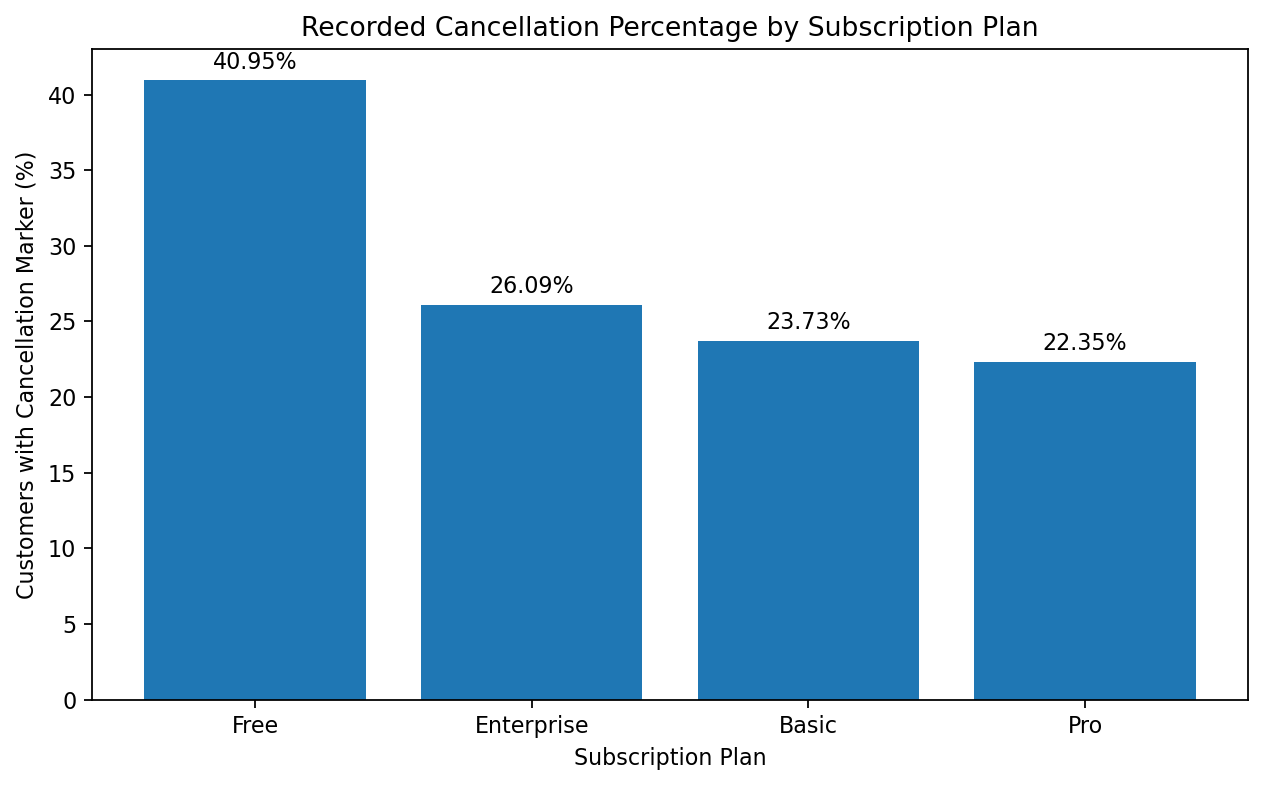

In [ ]:
# Visualize recorded cancellation percentages by subscription plan

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

bars = plt.bar(
    churn_by_plan["plan"],
    churn_by_plan["churn_rate_pct"]
)

plt.title("Recorded Cancellation Percentage by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Customers with Cancellation Marker (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cancellations_by_plan.png", dpi=160, bbox_inches="tight")
plt.show()



### 5.1 Recorded Cancellation Percentage by Subscription Plan

**Resultados de la visualización**

El gráfico compara la proporción de clientes con cancelación registrada entre los cuatro planes de Fit.ly.

Free presenta el mayor porcentaje (40,95 %), seguido por Enterprise (26,09 %), Basic (23,73 %) y Pro (22,35 %).

La diferencia sugiere que el segmento Free podría requerir una investigación específica sobre sus patrones de uso y las posibles razones de abandono.

No obstante, los porcentajes representan marcas de cancelación dentro del conjunto de datos y no tasas de churn correspondientes a un período confirmado.

**Findings (English)**

The Free plan had the highest recorded cancellation percentage at 40.95%, followed by Enterprise (26.09%), Basic (23.73%), and Pro (22.35%).

This visualization highlights differences in recorded cancellations across subscription plans.

The Free segment may warrant further investigation to better understand customer behavior and potential retention opportunities.

These percentages represent recorded cancellation markers rather than confirmed period-specific churn rates.



### 5.2 Support Resolution Time by Cancellation Status

Compararemos los tiempos promedio de resolución de soporte entre clientes con y sin cancelación registrada.

El objetivo es visualizar la magnitud de la diferencia observada e identificar si la experiencia de soporte podría constituir una dimensión relevante para investigar la retención de clientes.

Los valores corresponden al promedio de los tiempos medios de resolución por cliente, considerando únicamente a quienes registraron tickets.


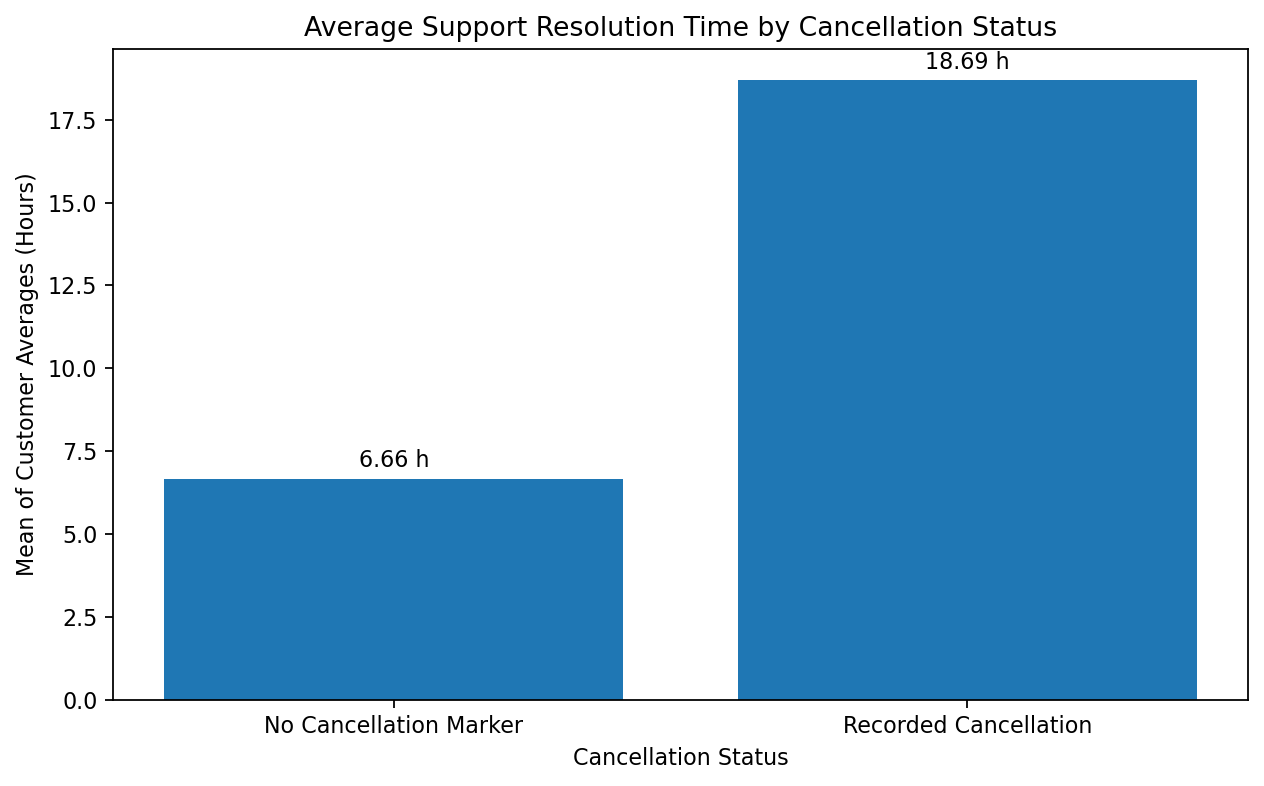

In [ ]:
# Visualize support resolution times by cancellation status

plt.figure(figsize=(8, 5))

cancellation_labels = {
    0: "No Cancellation Marker",
    1: "Recorded Cancellation",
}
plot_data = support_by_churn.sort_values("churn_flag")
bars = plt.bar(
    plot_data["churn_flag"].map(cancellation_labels),
    plot_data["avg_resolution_hours"],
)
plt.title("Average Support Resolution Time by Cancellation Status")
plt.xlabel("Cancellation Status")
plt.ylabel("Mean of Customer Averages (Hours)")

plt.bar_label(bars, fmt="%.2f h", padding=3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "support_resolution_by_cancellation.png", dpi=160, bbox_inches="tight")
plt.show()



### 5.2.1 Support Resolution Time — Visualization Results

**Resultados de la visualización**

El gráfico compara los tiempos promedio de resolución entre clientes con y sin cancelación registrada.

Los clientes con cancelación marcada presentan un promedio de 18,69 horas, frente a 6,66 horas en el grupo sin cancelación marcada.

La diferencia es de 12,03 horas, lo que equivale a un tiempo de resolución aproximadamente 2,8 veces mayor.

**Interpretación comercial**

Los tiempos prolongados de resolución podrían ser una variable relevante para investigar problemas de retención.

Se recomienda evaluar posibles mejoras en la atención de tickets con demoras elevadas y medir posteriormente su asociación con la retención de clientes.

**Limitaciones**

La visualización presenta el promedio de los tiempos medios de resolución por cliente, excluyendo aquellos sin tickets.

No se ha establecido la secuencia temporal entre las interacciones de soporte y las cancelaciones.

**Findings (English)**

Customers with recorded cancellations had an average customer-level support resolution time of 18.69 hours, compared with 6.66 hours among customers without cancellation markers.

The difference was 12.03 hours, representing approximately 2.8 times longer resolution times.

This finding suggests that prolonged support resolution times may be relevant when investigating customer retention.

Improving support responsiveness could be evaluated as a potential retention initiative.

**Limitations**

The chart represents the mean of customer-level resolution averages, excluding customers without support tickets.

The timing of support interactions relative to cancellations has not been established, and no causal relationship can be inferred.



### 5.3 User Activity by Cancellation Status

Compararemos la cantidad promedio de eventos de actividad registrados entre clientes con y sin cancelación marcada.

El objetivo es representar visualmente las diferencias de participación observadas durante el análisis exploratorio.

Los resultados incluyen clientes sin eventos registrados, cuyo conteo se representa mediante cero.

La visualización permitirá evaluar si la actividad registrada constituye una dimensión relevante para investigar posibles problemas de retención.


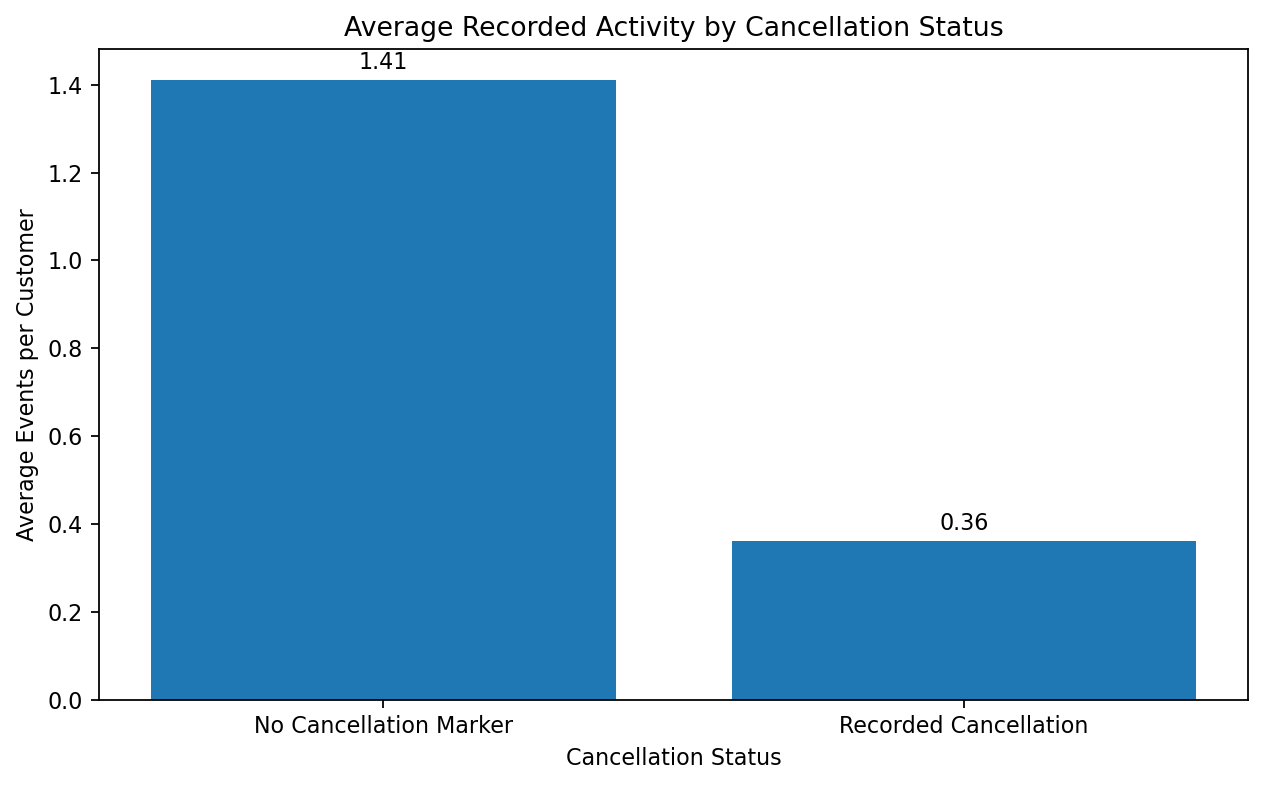

In [ ]:
# Visualize average activity by cancellation status

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plot_data = activity_by_churn.sort_values("churn_flag")
bars = plt.bar(
    plot_data["churn_flag"].map(cancellation_labels),
    plot_data["avg_events_per_customer"],
)
plt.title("Average Recorded Activity by Cancellation Status")
plt.xlabel("Cancellation Status")
plt.ylabel("Average Events per Customer")

# Add numeric labels
plt.bar_label(bars, fmt="%.2f", padding=3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "activity_by_cancellation.png", dpi=160, bbox_inches="tight")
plt.show()



### 5.3.1 User Activity — Visualization Results

**Resultados de la visualización**

El gráfico compara la cantidad promedio de eventos registrados por cliente entre los grupos con y sin cancelación marcada.

Los clientes sin cancelación registrada presentan 1,41 eventos promedio por cliente, frente a 0,36 entre aquellos con cancelación marcada.

La actividad registrada es aproximadamente 3,9 veces mayor en el primer grupo.

**Interpretación comercial**

Los resultados sugieren que la participación de los usuarios podría constituir una dimensión relevante para investigar problemas de retención.

Sería conveniente evaluar estrategias que fomenten la utilización de funcionalidades como el seguimiento de entrenamientos y medir posteriormente su relación con la permanencia de los clientes.

**Limitaciones**

La ausencia de eventos no demuestra necesariamente falta de uso.

No se ha establecido si los eventos registrados ocurrieron antes o después de las cancelaciones.

**Findings (English)**

Customers without cancellation markers averaged 1.41 recorded activity events per customer, compared with 0.36 among customers with recorded cancellations.

Recorded activity was approximately 3.9 times higher among customers without cancellation markers.

These findings suggest that user engagement may be relevant when investigating customer retention.

Initiatives encouraging workout tracking and other app interactions could be evaluated through controlled pilot programs.

**Limitations**

Missing activity records do not necessarily indicate that customers were inactive.

The timing of activity events relative to cancellations remains unknown, and the results do not establish causality.



### 5.4 Recorded Cancellation Percentage by Activity Group

Compararemos la proporción de cancelaciones registradas entre clientes con y sin eventos de actividad.

Esta visualización permitirá considerar el tamaño de cada grupo y comunicar la magnitud de las diferencias observadas.

Los porcentajes representan marcas de cancelación dentro de cada grupo, no tasas de churn correspondientes a un período confirmado.


In [ ]:
# Calculate cancellation percentages by activity group
cancellation_by_activity = con.sql("""
    SELECT
        CASE
            WHEN total_events = 0 THEN 'No Recorded Activity'
            ELSE 'Recorded Activity'
        END AS activity_group,
        COUNT(*) AS total_customers,
        SUM(churn_flag) AS churned_customers,
        ROUND(100.0 * SUM(churn_flag) / COUNT(*),2) AS cancellation_pct
    FROM customer_analytics
    GROUP BY activity_group
""").df()

cancellation_by_activity

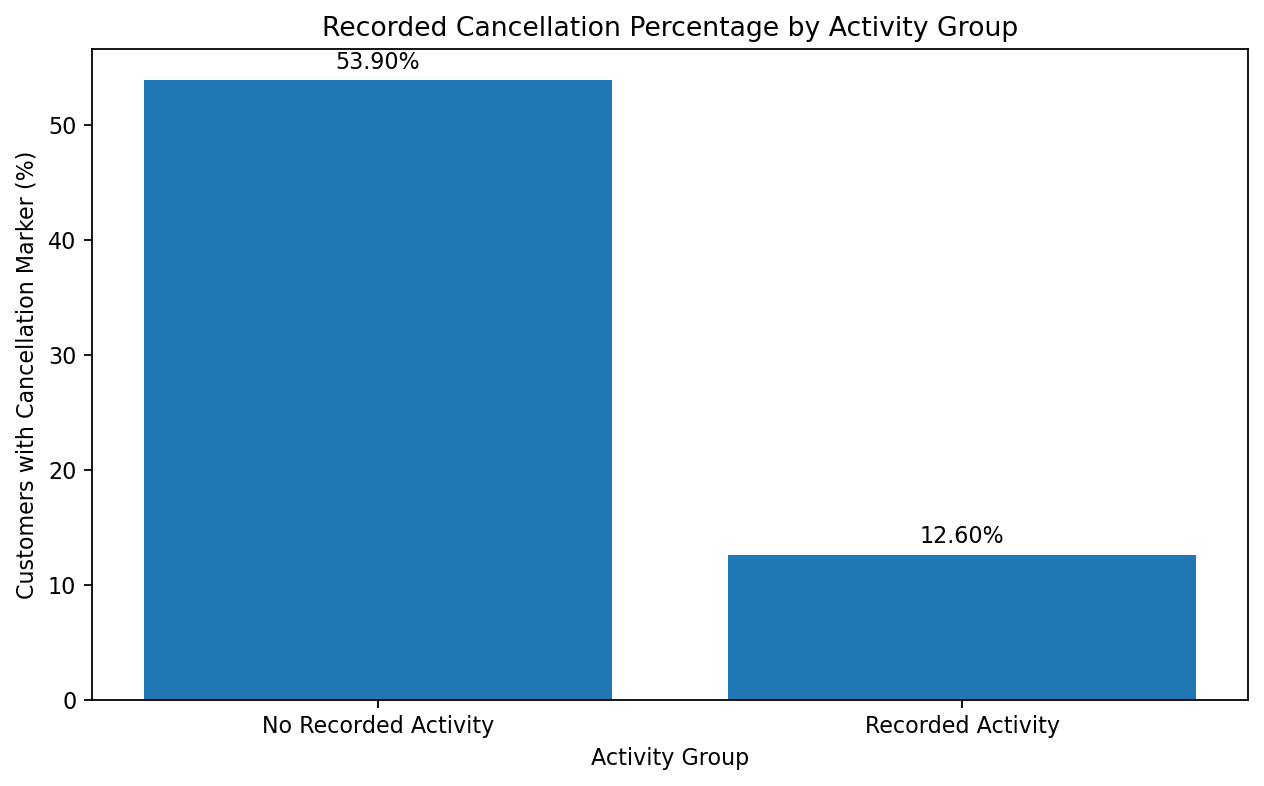

In [ ]:
# Visualize recorded cancellation percentages by activity group

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

# Create bars
bars = plt.bar(
    cancellation_by_activity["activity_group"],
    cancellation_by_activity["cancellation_pct"]
)

# Add title and axis labels
plt.title("Recorded Cancellation Percentage by Activity Group")
plt.xlabel("Activity Group")
plt.ylabel("Customers with Cancellation Marker (%)")

# Add percentage labels
plt.bar_label(bars, fmt="%.2f%%", padding=3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "cancellations_by_activity.png", dpi=160, bbox_inches="tight")
plt.show()



### 5.4.1 Recorded Cancellation Percentage by Activity Group — Results

**Resultados de la visualización**

Se comparó la proporción de cancelaciones registradas entre clientes con y sin eventos de actividad.

Entre los 154 clientes sin actividad registrada, 83 presentaron una cancelación marcada (53,90 %).

Entre los 246 clientes con actividad registrada, 31 presentaron una cancelación marcada (12,60 %).

La diferencia fue de 41,3 puntos porcentuales, con una proporción de cancelaciones aproximadamente 4,3 veces mayor entre clientes sin eventos registrados.

**Interpretación comercial**

Los resultados sugieren que la actividad registrada podría ser una variable relevante para investigar posibles problemas de retención.

Se propone evaluar un programa piloto de reactivación dirigido a clientes elegibles con baja actividad registrada.

La iniciativa podría fomentar el uso de funcionalidades como el seguimiento de entrenamientos mediante comunicaciones personalizadas y acciones de acompañamiento.

Su efectividad deberá evaluarse mediante indicadores de participación y retención, idealmente utilizando un grupo de control.

**Limitaciones**

La ausencia de eventos registrados no demuestra necesariamente inactividad real.

No se ha establecido la secuencia temporal entre actividad y cancelaciones.

Los resultados son descriptivos y no permiten atribuir causalidad.

**Findings (English)**

Customers without recorded activity had a cancellation marker percentage of 53.90%, compared with 12.60% among customers with recorded activity.

This represents a difference of 41.3 percentage points.

These findings suggest that recorded user engagement may be relevant when investigating customer retention.

A targeted re-engagement pilot could encourage eligible customers to use key features, particularly workout tracking.

The pilot should be evaluated using engagement and retention metrics, ideally with a control group.

**Limitations**

Missing activity records do not necessarily indicate inactivity.

The timing of activity relative to cancellations is unknown. Therefore, these results do not establish causality.



### 5.5 Distribution of Customers by Subscription Plan

Analizaremos la distribución de los clientes entre los cuatro planes de suscripción de Fit.ly.

El objetivo es comprender la composición de la base de clientes antes de interpretar las diferencias observadas en las cancelaciones.


In [ ]:
# Count customers by subscription plan
plan_counts = customer_analytics["plan"].value_counts()

plan_counts

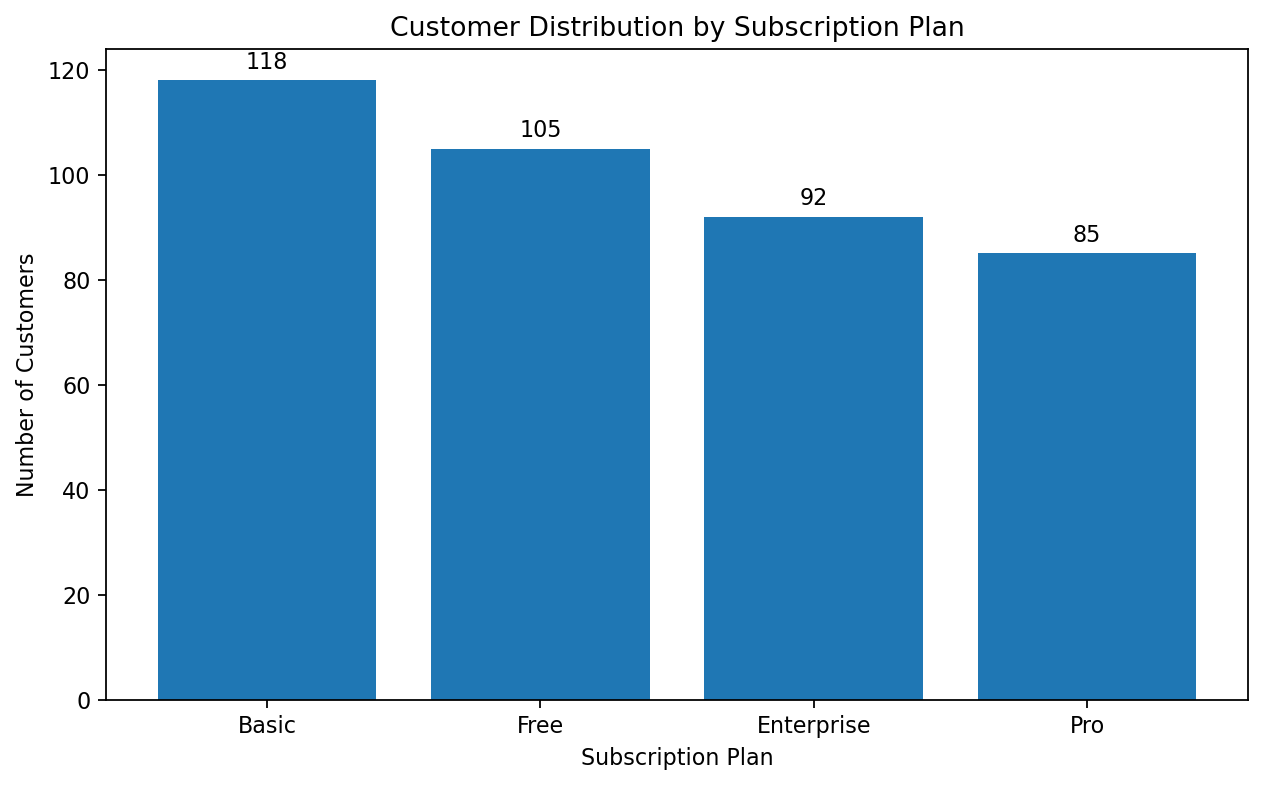

In [ ]:
# Visualize customer distribution by plan

plt.figure(figsize=(8, 5))

bars = plt.bar(
    plan_counts.index,
    plan_counts.values
)

plt.title("Customer Distribution by Subscription Plan")
plt.xlabel("Subscription Plan")
plt.ylabel("Number of Customers")

# Add numeric labels here
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "customers_by_plan.png", dpi=160, bbox_inches="tight")
plt.show()


In [ ]:
# Inspect support ticket distribution
customer_analytics["total_tickets"].describe()

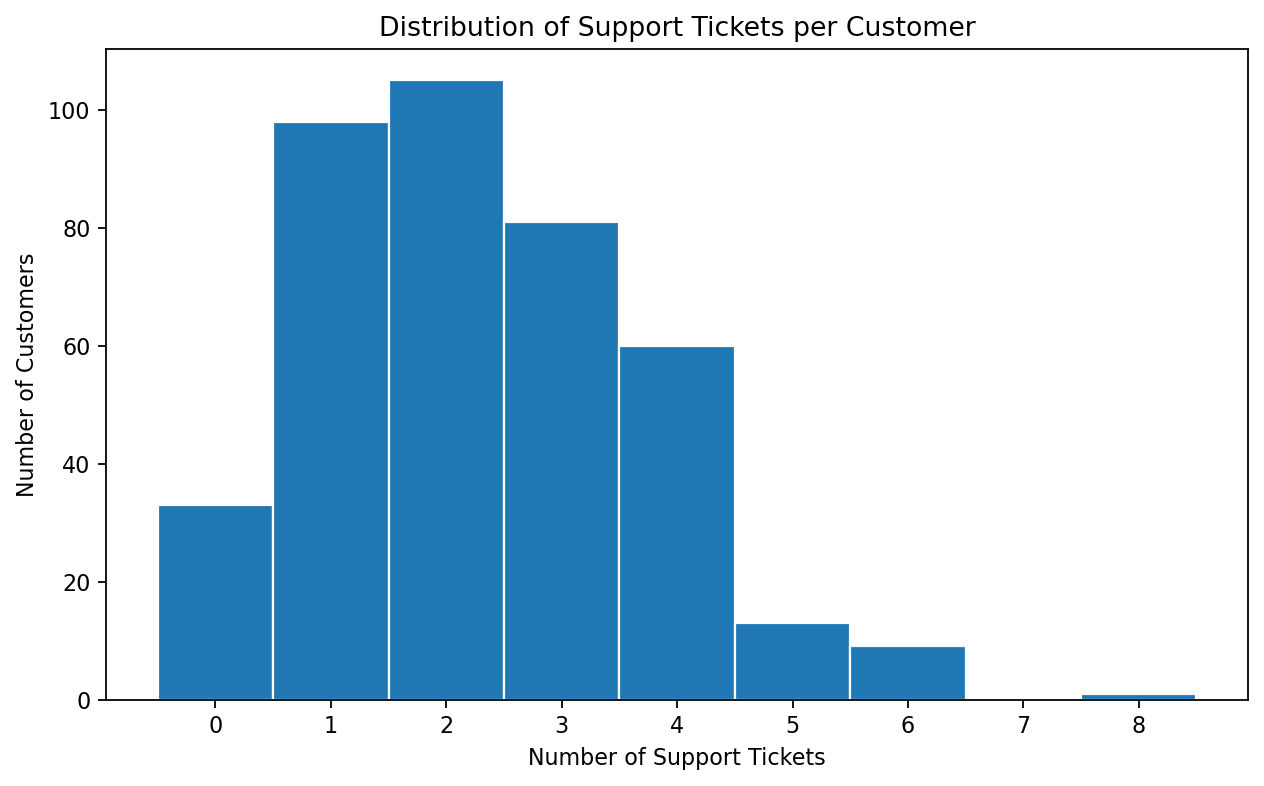

In [ ]:
# Visualize the distribution of support tickets per customer

plt.figure(figsize=(8, 5))

plt.hist(
    customer_analytics["total_tickets"],
    bins=np.arange(-0.5, 9.5, 1),
    edgecolor="white"
)

plt.title("Distribution of Support Tickets per Customer")
plt.xlabel("Number of Support Tickets")
plt.ylabel("Number of Customers")
plt.xticks(range(0, 9))
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tickets_per_customer.png", dpi=160, bbox_inches="tight")
plt.show()



### 5.5.1 Customer Distribution by Plan — Findings

The Basic plan had the largest customer base, with 118 customers, followed by Free (105), Enterprise (92), and Pro (85).

All four subscription plans were represented in the dataset.

This distribution provides context for comparing recorded cancellation percentages across plans with different numbers of customers.

### 5.6.1 Support Ticket Distribution — Findings

The distribution of support tickets was concentrated between one and four tickets per customer.

The median was two tickets, and the mean was approximately 2.30 tickets per customer.

A small number of customers had higher ticket counts, with a maximum of eight tickets.

These findings describe the frequency of recorded support interactions but do not establish whether higher ticket counts reflect poor customer experiences.




## 6. Business Recommendations

### 6.1 Targeted User Re-engagement Pilot

**Recomendación comercial**

Se propone evaluar un programa piloto de reactivación dirigido a clientes elegibles con baja actividad registrada.

El análisis identificó una proporción de cancelaciones marcadas del 53,90 % entre clientes sin eventos registrados, frente al 12,60 % entre aquellos con actividad.

Estos resultados sugieren una oportunidad para investigar estrategias que fomenten la participación mediante seguimiento de entrenamientos, recordatorios personalizados y acciones de acompañamiento.

**Implementación propuesta**

1. Identificar clientes con suscripciones activas confirmadas y baja actividad reciente.
2. Dividir aleatoriamente a los clientes elegibles entre un grupo de intervención y un grupo de control.
3. Aplicar acciones de reactivación al grupo de intervención.
4. Evaluar ambos grupos durante un período definido, inicialmente 30 días.
5. Comparar los resultados para determinar si la iniciativa mejora la retención.

**Indicadores de desempeño**

- KPI principal: Retention Rate a 30 días.
- KPI secundario: Activation Rate.
- KPI secundario: Average Workout Events per Customer.

**Limitaciones**

Los datos actuales no confirman la condición activa de todos los clientes ni permiten establecer el momento exacto de las cancelaciones.

Por tanto, será necesario disponer de estados de suscripción actualizados y fechas relevantes para medir adecuadamente la retención.

**Business Recommendation (English)**

Fit.ly should evaluate a targeted re-engagement pilot for eligible customers with low recorded activity.

The analysis found a cancellation marker percentage of 53.90% among customers without recorded activity, compared with 12.60% among customers with activity records.

The proposed initiative would encourage engagement through personalized reminders, workout tracking guidance, and simple fitness challenges.

Eligible customers should be randomly assigned to an intervention group or a control group.

The primary KPI would be the 30-day retention rate, supported by activation rate and average workout tracking events per customer.

Results should be compared between groups to evaluate whether the intervention improves retention.

**Limitations**

The available dataset does not confirm active subscription status for all customers or establish cancellation dates.

Additional subscription data will be required to measure retention reliably.

The observed relationship between activity and cancellation does not establish causality.



## 7. Business Metric

### Recorded Cancellation Percentage

**Metric definition**

Recorded Cancellation Percentage measures the proportion of customer accounts with a recorded cancellation marker in the available dataset.

It is calculated by dividing the number of accounts with a cancellation marker by the total number of accounts and multiplying by 100.

**Initial value**

The dataset contains 400 customer accounts, including 114 accounts with recorded cancellations.

The initial Recorded Cancellation Percentage is **28.50%**.

**Business application**

Fit.ly can use this metric as a descriptive baseline to investigate cancellation patterns across customer segments.

For future monitoring, the company should collect confirmed subscription statuses and cancellation dates.

The proposed re-engagement pilot should use the **30-day Retention Rate** as its primary performance indicator.

Retention should be compared between eligible customers receiving the intervention and a control group over the same period.

**Limitations**

The available dataset does not establish when cancellations occurred.

Blank cancellation fields have not been independently confirmed as active subscriptions.

Therefore, the initial 28.50% is not a confirmed monthly or annual churn rate and cannot be directly compared with a future 30-day retention rate.


In [ ]:
# Calculate the recorded cancellation baseline

cancellation_baseline = con.sql("""
    SELECT
       COUNT(*) AS total_customers,
       SUM(churn_flag) AS recorded_cancellations,
       ROUND(100.0 * SUM(churn_flag)/COUNT(*),2) AS cancellation_pct
    FROM customer_analytics
""").df()

cancellation_baseline